In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score,
                             confusion_matrix, silhouette_score)
from sklearn.cluster import KMeans

df = pd.read_csv("heart.csv", encoding="utf-8-sig")
print(df.shape)
print(df.dtypes)
df = df.drop_duplicates()
print(df.shape)

(1025, 14)
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object
(302, 14)


             age         sex          cp    trestbps        chol         fbs  \
count  302.00000  302.000000  302.000000  302.000000  302.000000  302.000000   
mean    54.42053    0.682119    0.963576  131.602649  246.500000    0.149007   
std      9.04797    0.466426    1.032044   17.563394   51.753489    0.356686   
min     29.00000    0.000000    0.000000   94.000000  126.000000    0.000000   
25%     48.00000    0.000000    0.000000  120.000000  211.000000    0.000000   
50%     55.50000    1.000000    1.000000  130.000000  240.500000    0.000000   
75%     61.00000    1.000000    2.000000  140.000000  274.750000    0.000000   
max     77.00000    1.000000    3.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  302.000000  302.000000  302.000000  302.000000  302.000000  302.000000   
mean     0.526490  149.569536    0.327815    1.043046    1.397351    0.718543   
std      0.526027   22.903527    0.4

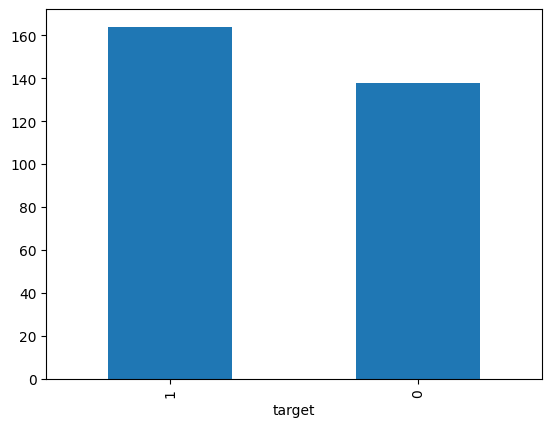

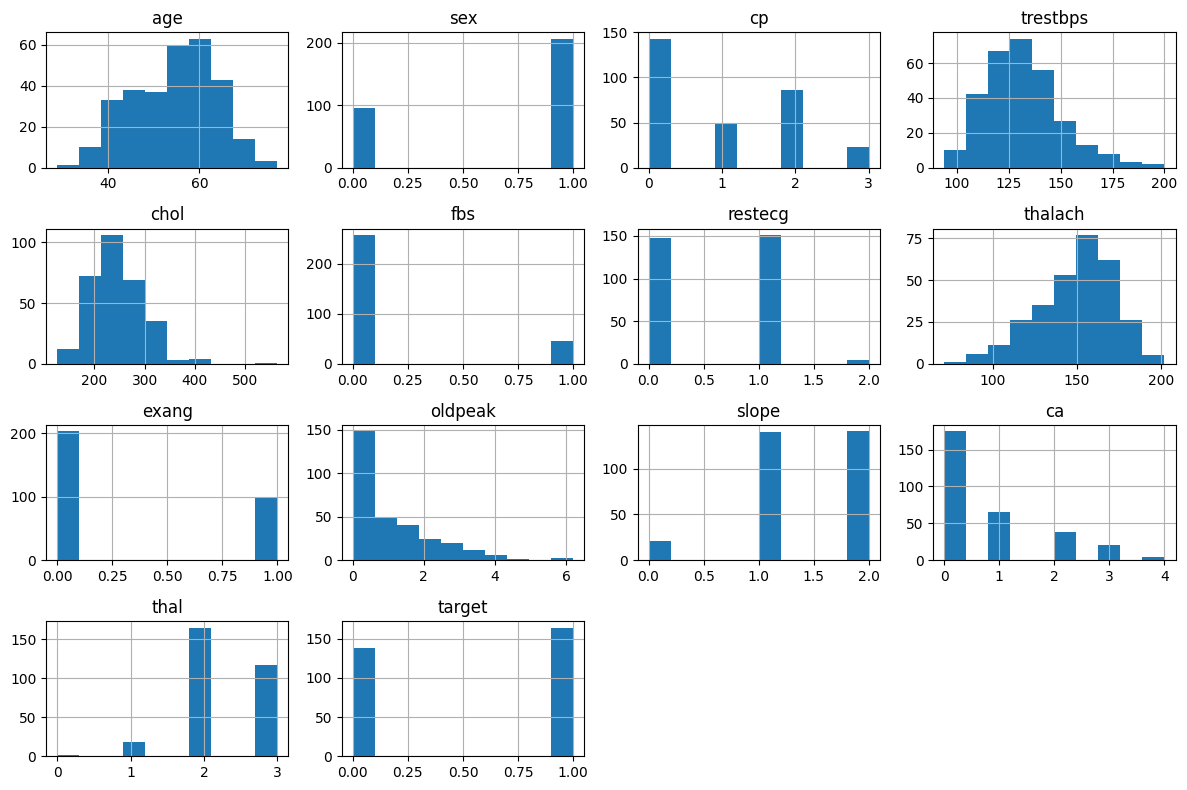

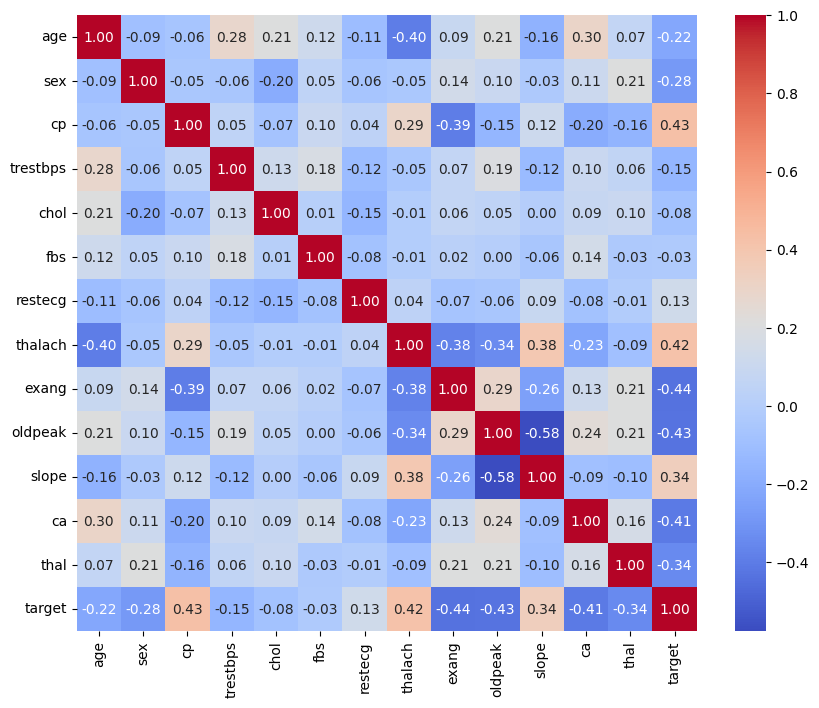

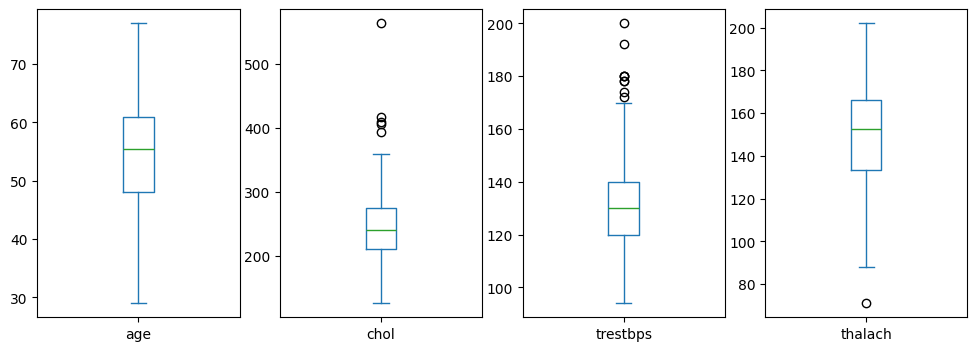

In [ ]:
print(df.describe())
print(df["target"].value_counts())

df["target"].value_counts().plot(kind="bar")
plt.show()

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

df[["age", "chol", "trestbps", "thalach"]].plot(
    kind="box", subplots=True, layout=(1, 4), figsize=(12, 4))
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

X = df_clean.drop("age", axis=1)
y = df_clean["age"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_te = scaler.transform(X_te)

model = LinearRegression()
model.fit(X_tr, y_tr)
pred = model.predict(X_te)

mse = mean_squared_error(y_te, pred)
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2:", r2_score(y_te, pred))

MSE: 47.26021544837167
RMSE: 6.874606566805963
R2: 0.31489589657559114


Acc: 0.7704918032786885 | Prec: 0.7027027027027027 | Rec: 0.896551724137931
[[21 11]
 [ 3 26]]


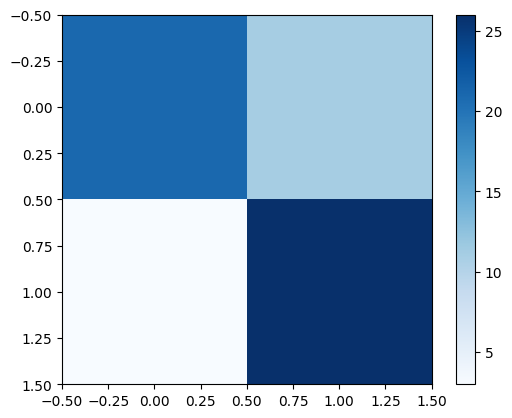

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_tr, X_te, y_tr, y_te = train_test_split(
    df_clean.drop("target", axis=1),
    df_clean["target"],
    test_size=0.2,
    random_state=42,
)

s = StandardScaler()
X_tr = s.fit_transform(X_tr)
X_te = s.transform(X_te)

m = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
pred = m.predict(X_te)
cm = confusion_matrix(y_te, pred)

print(
    "Acc:",
    accuracy_score(y_te, pred),
    "| Prec:",
    precision_score(y_te, pred),
    "| Rec:",
    recall_score(y_te, pred),
)
print(cm)

plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.show()

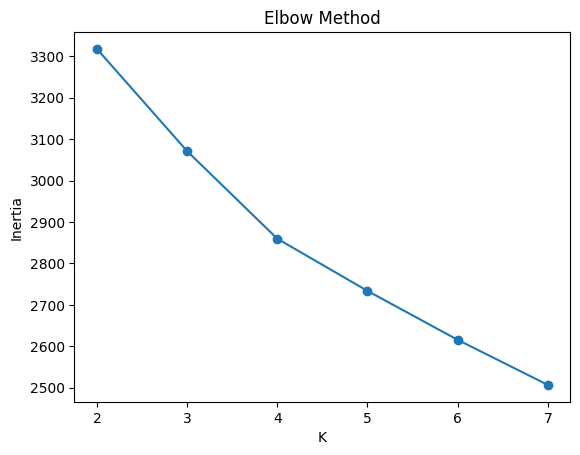

Silhouette Score (K=2): 0.1680601289239488


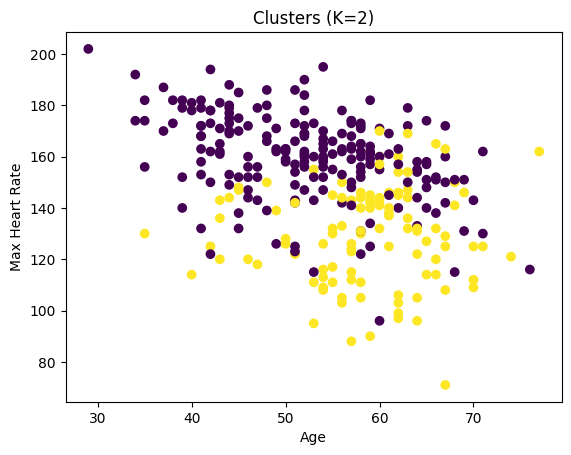

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(df_clean.drop("target", axis=1))

# 1. Elbow Method
inertias = []
for k in range(2, 8):
  inertias.append(
      KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_
  )

plt.plot(range(2, 8), inertias, marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# 2. K-Means at K=2 + Scatter Plot
labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X)
print("Silhouette Score (K=2):", silhouette_score(X, labels))

plt.scatter(df_clean["age"], df_clean["thalach"], c=labels)
plt.xlabel("Age")
plt.ylabel("Max Heart Rate")
plt.title("Clusters (K=2)")
plt.show()